In [62]:
import pandas as pd 
from skbio.stats.composition import clr
import re
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import statsmodels.api as sm 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.ensemble import RandomForestClassifier

In [64]:
df1 = pd.read_csv("/Users/angelinagaines0506/Downloads/meta2db_microbiome profiles/2020_ZhuF_wint2023_noHum_mhl40.rcf.data.csv") 

/var/folders/ly/br2g_8852bl094gy3qx9_qkc0000gn/T/ipykernel_76496/4159531129.py:1: DtypeWarning: Columns (0: Samples, 1: ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15, 2: ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1, 3: ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2, 4: ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15, 5: ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1, 6: ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2, 7: ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15, 8: ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1, 9: ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_n

In [3]:
df1.head()

,Samples,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,...,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,Details,Details.1
0,Stats,cnt,una,sco,cnt,una,sco,cnt,una,sco,...,una,sco,cnt,una,sco,cnt,una,sco,Rank,Name
1,Id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,37379736,2819131,154.17870273358386,28573223,827983,124.01305771619836,31505415,2350116,165.28984217737874,...,529257,109.37818512805933,36592959,2541092,156.50612809224026,30750746,1923119,168.65831900839595,no_rank,root
3,2,29885955,636424,156.8055086281383,24825742,513236,123.32350697864774,27185997,1041777,166.7879624368146,...,411389,108.52598948270007,32034174,904685,154.61001902577505,27683492,810863,168.71631243196995,superkingdom,Bacteria
4,1224,122033,305,111.5444903721046,227193,2492,131.0779537358411,113559,630,122.65260015773868,...,1023,115.12872238981137,291675,518,146.14952300924358,365966,241,159.69903159446395,phylum,Proteobacteria


cnt is accumulated count
una is unaccumulated count
score 

In [65]:
df1 = df1.iloc[2:].reset_index(drop = True)

In [66]:
zero = df1.columns[df1.eq(0).all()]

num_zero_columns = df1.eq(0).all().sum()

print(zero)

print(num_zero_columns)

Index([], dtype='str')
0


In [67]:
na = df1.columns[df1.isna().all()]

num_na_columns = df1.isna().all().sum()

print(na)

print(num_na_columns)

Index([], dtype='str')
0


In [68]:
print(df1[:20])

    Samples  \
0         1   
1         2   
2      1224   
3      1236   
4     33811   
5     83406   
6    883811   
7   1235284   
8    947516   
9   1248727   
10  1563632   
11  1778877   
12  1778878   
13  1913989   
14  2070539   
15  2496632   
16    50423   
17    86473   
18  1665201   
19    72273   

   ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15  \
0                                            37379736                                              
1                                            29885955                                              
2                                              122033                                              
3                                               96938                                              
4                                                  41                                              
5                                                  28                               

In [69]:
print(df1["Details"].unique())

<ArrowStringArray>
[         'no_rank',     'superkingdom',           'phylum',
            'class',          'species',          'isolate',
            'order',           'family',            'genus',
           'strain',       'subspecies',    'species_group',
 'species_subgroup',        'subfamily',         'serotype',
        'serogroup',          'variety',  'forma_specialis',
          'biotype',            'tribe',         'subgenus',
        'subphylum',         'suborder',         'subclass',
          'kingdom',       'superorder',         'subtribe',
          'section',            'forma',       'subkingdom',
       'infraorder',      'superfamily',        'parvorder',
       'superclass',       'infraclass',           'cohort',
           'series',        'subcohort']
Length: 38, dtype: str


In [70]:
df1_taxonomy = df1.copy()

df1_taxonomy = df1_taxonomy.set_index("Details.1")

df1_species = df1_taxonomy[df1_taxonomy["Details"] == "species"] 

df1_genera = df1_taxonomy[df1_taxonomy["Details"] == "genus"] 

In [71]:
df1_species.head()

,Samples,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,...,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,Details
Details.1,,,,,,,,,,,,,,,,,,,,,
gamma proteobacterium HdN1,83406,28,28,49.82694031901967,0,0,-inf,82,82,58.091283179873116,...,0,0,-inf,0,0,-inf,29,29,52.074287204570716,species
Isorropodon fossajaponicum symbiont,883811,0,0,-inf,0,0,-inf,0,0,-inf,...,0,0,-inf,0,0,-inf,0,0,-inf,species
gamma proteobacterium SS-5,947516,0,0,-inf,0,0,-inf,17,17,48.243194172010135,...,0,0,-inf,15,15,49.266666666666666,39,39,48.205128205128204,species
endosymbiont of unidentified scaly snail isolate Monju,1248727,0,0,-inf,0,0,-inf,0,0,-inf,...,0,0,-inf,0,0,-inf,0,0,-inf,species
gamma proteobacterium symbiont of Plautia stali,1563632,0,0,-inf,0,0,-inf,0,0,-inf,...,0,0,-inf,0,0,-inf,0,0,-inf,species


In [72]:
df1_species[50:100]

,Samples,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,...,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.1,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15.2,Details
Details.1,,,,,,,,,,,,,,,,,,,,,
Pseudomonas knackmussii,65741,0,0,-inf,16,16,42.8125,0,0,-inf,...,14,3,42.09557822261602,0,0,-inf,0,0,-inf,species
Pseudomonas thivervalensis,86265,0,0,-inf,0,0,-inf,0,0,-inf,...,0,0,-inf,0,0,-inf,0,0,-inf,species
Pseudomonas vancouverensis,95300,0,0,-inf,0,0,-inf,0,0,-inf,...,0,0,-inf,0,0,-inf,0,0,-inf,species
Pseudomonas frederiksbergensis,104087,14,14,60.30538015411904,13,13,41.76923076923077,12,12,66.8309431010168,...,0,0,-inf,0,0,-inf,0,0,-inf,species
Pseudomonas psychrophila,122355,355,355,94.35334929308469,30,30,63.54578828555277,291,291,133.27097032495604,...,377,377,138.36479979297675,12,12,122.65182948489797,48,48,120.10755500692642,species
Pseudomonas aeruginosa,287,62,62,89.6822895015214,67,67,130.1534127029291,93,93,130.48001180044676,...,121,121,130.28751137239206,953,953,100.44663550190822,181,181,138.78696977655727,species
Pseudomonas mendocina,300,0,0,-inf,13,13,49.23076923076923,0,0,-inf,...,30,30,49.01421848111667,0,0,-inf,0,0,-inf,species
Pseudomonas alcaligenes,43263,0,0,-inf,0,0,-inf,8,8,45.75825214724777,...,0,0,-inf,0,0,-inf,0,0,-inf,species
Pseudomonas citronellolis,53408,20,20,44.5,0,0,-inf,21,21,47.86365186546495,...,0,0,-inf,15,15,47.46666666666667,96,96,46.458333333333336,species


In [73]:
print("number of rows:", len(df1_species.index)) 

number of rows: 11517


In [74]:
keep = [c for c in df1_species.columns if not re.search(r"\.\d+$", c)] 
df2_species = df1_species[keep].copy()
df2_species.head()

,Samples,ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855789_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855790_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855791_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855792_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855793_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855794_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,...,ERR2855948_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855949_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855950_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855951_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855952_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855953_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855954_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855955_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,ERR2855956_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,Details
Details.1,,,,,,,,,,,,,,,,,,,,,
gamma proteobacterium HdN1,83406,28,0,82,0,0,0,40,0,0,...,0,0,0,0,0,0,0,0,29,species
Isorropodon fossajaponicum symbiont,883811,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,species
gamma proteobacterium SS-5,947516,0,0,17,0,0,339,0,8,210,...,23,9,0,0,32,0,0,15,39,species
endosymbiont of unidentified scaly snail isolate Monju,1248727,0,0,0,0,0,0,0,0,0,...,0,11,0,0,0,0,0,0,0,species
gamma proteobacterium symbiont of Plautia stali,1563632,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,species


In [75]:
df2 = pd.read_csv("/Users/angelinagaines0506/Downloads/meta2db_metadata.csv", encoding = "mac_roman") 

In [76]:
df2.head()

,iodbID,investigation_type,project_name,experimental_factor,pub_date,pub_abstract,lat_lon,geo_loc_name,collection_date,env_biome,...,travel_destination,treat_resp,treatment,triglycerides,tumor_size,ulceration_scc,urea_nitrogen,visit_number,x5_asa,years_diag
0,6594.0,metagenome,2013_KarlssonFH,"Gut metagenome in European women with normal, ...",5/29/13,Type 2 diabetes (T2D) is a result of complex g...,not available,Sweden,not available,not available,...,not applicable,not applicable,not applicable,70.60496073,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
1,6595.0,metagenome,2013_KarlssonFH,"Gut metagenome in European women with normal, ...",5/29/13,Type 2 diabetes (T2D) is a result of complex g...,not available,Sweden,not available,not available,...,not applicable,not applicable,not applicable,106.6919407,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
2,6596.0,metagenome,2013_KarlssonFH,"Gut metagenome in European women with normal, ...",5/29/13,Type 2 diabetes (T2D) is a result of complex g...,not available,Sweden,not available,not available,...,not applicable,not applicable,not applicable,72.95845943,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
3,6597.0,metagenome,2013_KarlssonFH,"Gut metagenome in European women with normal, ...",5/29/13,Type 2 diabetes (T2D) is a result of complex g...,not available,Sweden,not available,not available,...,not applicable,not applicable,not applicable,42.36297644,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
4,6598.0,metagenome,2013_KarlssonFH,"Gut metagenome in European women with normal, ...",5/29/13,Type 2 diabetes (T2D) is a result of complex g...,not available,Sweden,not available,not available,...,not applicable,not applicable,not applicable,80.80345506,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable


In [77]:
df2 = df2[df2["project_name"] == "2020_ZhuF"]

In [78]:
df2.head()

,iodbID,investigation_type,project_name,experimental_factor,pub_date,pub_abstract,lat_lon,geo_loc_name,collection_date,env_biome,...,travel_destination,treat_resp,treatment,triglycerides,tumor_size,ulceration_scc,urea_nitrogen,visit_number,x5_asa,years_diag
5982,10970.0,metagenome,2020_ZhuF,Metagenome-wide association of gut microbiome ...,3/31/20,Evidence is mounting that the gut-brain axis p...,not available,China:Xian,not available,not available,...,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
5983,11069.0,metagenome,2020_ZhuF,Metagenome-wide association of gut microbiome ...,3/31/20,Evidence is mounting that the gut-brain axis p...,not available,China:Xian,not available,not available,...,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
5984,10996.0,metagenome,2020_ZhuF,Metagenome-wide association of gut microbiome ...,3/31/20,Evidence is mounting that the gut-brain axis p...,not available,China:Weinan,not available,not available,...,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
5985,10989.0,metagenome,2020_ZhuF,Metagenome-wide association of gut microbiome ...,3/31/20,Evidence is mounting that the gut-brain axis p...,not available,China:Lintong,not available,not available,...,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable
5986,11013.0,metagenome,2020_ZhuF,Metagenome-wide association of gut microbiome ...,3/31/20,Evidence is mounting that the gut-brain axis p...,not available,China:Hanzhong,not available,not available,...,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable,not applicable


In [79]:
df2_species = df2_species.T

In [80]:
df2_species.head()

Details.1,gamma proteobacterium HdN1,Isorropodon fossajaponicum symbiont,gamma proteobacterium SS-5,endosymbiont of unidentified scaly snail isolate Monju,gamma proteobacterium symbiont of Plautia stali,gamma proteobacterium 10BT,gamma proteobacterium NT2-2,Gammaproteobacteria bacterium,Gammaproteobacteria bacterium ESL0073,Gammaproteobacteria bacterium (ex Lamellibrachia satsuma),...,Cloning vector pPV512,Cloning vector pMSW107,Shuttle vector pAM1,Cloning vector pCA-DEST2303,Cloning vector pMJc01,Vector pPTK-BC-IPR,Shuttle vector pG106-KA,Shuttle vector pCMB58-ermF-Dys,synthetic construct,synthetic Escherichia coli Syn61
Samples,83406,883811,947516,1248727,1563632,1778877,1778878,1913989,2070539,2496632,...,1821230,1892242,1945223,2081755,2600301,2829358,2961897,2978120,32630,2580236
ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,28,0,0,0,0,0,0,11,0,0,...,0,0,0,213,0,0,0,0,80,0
ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,0,0,0,0,0,0,0,0,0,0,...,0,0,0,77,0,0,0,0,41,15
ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,82,0,17,0,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,89,21
ERR2855789_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,24,0


In [84]:
og_abundances = df2_species.drop(index = ["Samples", "Details"])
og_abundances = og_abundances.apply(pd.to_numeric)

# get the fraction of non-zero abundances for each column
nonzero_freqs = (og_abundances > 0).mean(axis=0)

# only keep microbes in at least 15% of the patients
filt_abundances = og_abundances.loc[:, nonzero_freqs >= 0.15]
print(f"{filt_abundances.shape[1]} microbes kept after dropping those not present in at least 15% of subjects")

# need to add a pseudocount to deal with zeros
pseudo_count = 1e-6
pseudo_abundances = filt_abundances + pseudo_count

# apply the CLR transformation
clr_abundances = clr(pseudo_abundances)
clr_df = pd.DataFrame(clr_abundances, columns=filt_abundances.columns, index=filt_abundances.index)
clr_df.head()

2480 microbes kept after dropping those not present in at least 15% of subjects


Details.1,gamma proteobacterium HdN1,gamma proteobacterium SS-5,Gammaproteobacteria bacterium,Candidatus Thiothrix anitrata,Pseudomonas taetrolens,uncultured Pseudomonas sp.,Pseudomonas frederiksbergensis,Pseudomonas psychrophila,Pseudomonas aeruginosa,Pseudomonas mendocina,...,CRESS virus sp.,CRESS virus sp. ctBnw2,Corticoviridae sp.,unidentified,uncultured prokaryote,uncultured organism,uncultured microorganism,unidentified plasmid,synthetic construct,synthetic Escherichia coli Syn61
ERR2855786_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,7.567394,-9.580321,6.633085,-9.580321,7.948762,-9.580321,6.874247,10.107308,8.362324,-9.580321,...,-9.580321,-9.580321,-9.580321,-9.580321,12.532484,16.952894,6.800139,14.587042,8.617217,-9.580321
ERR2855787_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,-10.795158,-10.795158,-10.795158,-10.795158,-10.795158,-10.795158,5.585302,6.421550,7.225045,5.585302,...,-10.795158,-10.795158,-10.795158,4.966263,11.982488,14.701881,5.322938,13.144019,6.733925,5.728403
ERR2855788_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,8.217409,6.643903,5.890132,6.755129,7.524262,-10.004821,6.295597,9.484013,8.343289,-10.004821,...,8.154495,-10.004821,-10.004821,6.295597,12.722489,15.205428,-10.004821,13.481236,8.299326,6.855212
ERR2855789_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,-6.270157,-6.270157,-6.270157,-6.270157,-6.270157,-6.270157,-6.270157,11.849418,17.128567,-6.270157,...,9.624795,-6.270157,-6.270157,-6.270157,14.882290,18.869827,-6.270157,17.816743,10.723407,-6.270157
ERR2855790_HiSeq_X_Ten_paired_end_sequencing_Metagenomics_of_fecal_human_hum_removed_nt_mhl15,-9.420918,-9.420918,-9.420918,-9.420918,-9.420918,-9.420918,6.792488,9.198613,8.401925,-9.420918,...,8.083472,7.761888,-9.420918,-9.420918,12.917370,17.768892,7.439115,14.692720,6.340503,-9.420918


In [85]:
scaler = StandardScaler()
clrS = scaler.fit_transform(clr_df) 

In [91]:
df2 = df2.rename(columns={"filename_match": "Samples"})

#df2_species = df2_species.rename_axis("Samples").reset_index()

df2_species["Samples"] = df2_species["Samples"].str.extract(r"(ERR\d+)", expand = False)

merged_samples_species = df2[["Samples", "health_disease_stat"]].merge(df2_species, on = "Samples", how = "inner")

print(merged_samples_species.shape)

(171, 11519)


In [92]:
merged_samples_species.head()

,Samples,health_disease_stat,gamma proteobacterium HdN1,Isorropodon fossajaponicum symbiont,gamma proteobacterium SS-5,endosymbiont of unidentified scaly snail isolate Monju,gamma proteobacterium symbiont of Plautia stali,gamma proteobacterium 10BT,gamma proteobacterium NT2-2,Gammaproteobacteria bacterium,...,Cloning vector pPV512,Cloning vector pMSW107,Shuttle vector pAM1,Cloning vector pCA-DEST2303,Cloning vector pMJc01,Vector pPTK-BC-IPR,Shuttle vector pG106-KA,Shuttle vector pCMB58-ermF-Dys,synthetic construct,synthetic Escherichia coli Syn61
0,ERR2855786,control,28,0,0,0,0,0,0,11,...,0,0,0,213,0,0,0,0,80,0
1,ERR2855787,control,0,0,0,0,0,0,0,0,...,0,0,0,77,0,0,0,0,41,15
2,ERR2855788,diseased,82,0,17,0,0,0,0,8,...,0,0,0,0,0,0,0,0,89,21
3,ERR2855789,control,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,24,0
4,ERR2855790,control,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,7,0


In [61]:
print("names of columns:", merged_samples_species.columns.tolist()) 

names of columns: ['Samples', 'health_disease_stat', 'gamma proteobacterium HdN1', 'Isorropodon fossajaponicum symbiont', 'gamma proteobacterium SS-5', 'endosymbiont of unidentified scaly snail isolate Monju', 'gamma proteobacterium symbiont of Plautia stali', 'gamma proteobacterium 10BT', 'gamma proteobacterium NT2-2', 'Gammaproteobacteria bacterium', 'Gammaproteobacteria bacterium ESL0073', 'Gammaproteobacteria bacterium (ex Lamellibrachia satsuma)', 'uncultured Gammaproteobacteria bacterium', 'uncultured gamma proteobacterium Rifle_16ft_4_minimus_5046', 'Francisella tularensis', 'Francisella persica', 'Francisella philomiragia', 'Francisella orientalis', 'Francisella halioticida', 'Francisella hispaniensis', 'Francisella noatunensis', 'Francisella frigiditurris', 'Francisella adeliensis', 'Francisella marina', 'Francisella sp. LA112445', 'Francisella sp. FSC1006', 'Allofrancisella frigidaquae', 'Allofrancisella inopinata', 'Thiomicrospira aerophila', 'Thiomicrospira cyclica', 'Pisci

In [105]:
y = (merged_samples_species["health_disease_stat"] == "diseased").astype(int)
print(y[:10])

0    0
1    0
2    1
3    0
4    0
5    1
6    0
7    1
8    0
9    1
Name: health_disease_stat, dtype: int64


In [100]:
X = clrS 
pca = PCA()
X_pca = pca.fit_transform(X)

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 41)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

m = sm.GLM(y_train, X_train, family = sm.families.Binomial())

alpha1 = np.arange(0.3, 1.21, 0.1)
alpha2 = np.arange(0.0, 1.01, 0.1)


number_models = (len(alpha1) * len(alpha2))

print(f"{number_models} will run") 

results_train = np.zeros((len(alpha1), len(alpha2)))
results_test = np.zeros((len(alpha1), len(alpha2)))

for i, a1 in enumerate(alpha1):
    for j, a2 in enumerate(alpha2):
    
        result_reg = m.fit_regularized(method = 'elastic_net', alpha = a1, L1_wt = a2, maxiter = 10000)

        probs_train  = result_reg.predict(X_train)
        probs_test  = result_reg.predict(X_test)
    
        probsR_train = np.round(probs_train)
        probsR_test = np.round(probs_test)
    
        Ypred_train  = probsR_train.astype(int)
        Ypred_test  = probsR_test.astype(int) 

        acc_train = 100*np.mean(np.asarray(Ypred_train) == np.asarray(y_train))
        acc_test = 100*np.mean(np.asarray(Ypred_test) == np.asarray(y_test))

        results_train[i, j] = acc_train
        results_test[i, j] = acc_test
print(results_train)
print(results_test)

110 will run
[[100.         100.          98.52941176  93.38235294  88.97058824
   72.05882353  67.64705882  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.         100.          94.85294118  88.23529412  66.91176471
   50.73529412  50.73529412  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.          99.26470588  91.17647059  75.          50.73529412
   50.73529412  50.73529412  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.          97.79411765  87.5         67.64705882  50.73529412
   50.73529412  50.73529412  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.          96.32352941  79.41176471  50.73529412  50.73529412
   50.73529412  50.73529412  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.          95.58823529  66.91176471  50.73529412  50.73529412
   50.73529412  50.73529412  50.73529412  50.73529412  50.73529412
   50.73529412]
 [100.          92.64705882  67.64705882  50.73529412  50.73529412
   50.73529412  50.7

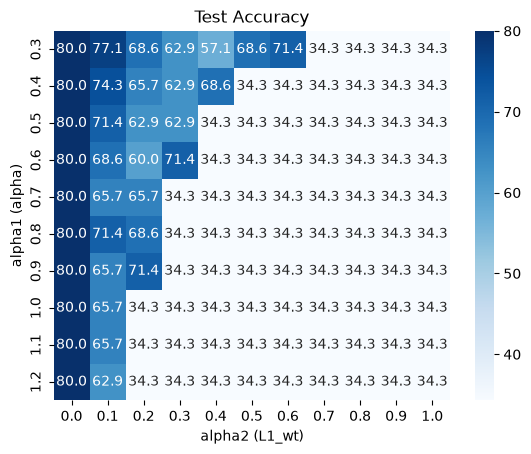

In [102]:
sns.heatmap(results_test, annot = True, fmt = ".1f", cmap = "Blues", xticklabels = np.round(alpha2, 1), yticklabels = np.round(alpha1, 1)) 
plt.xlabel("alpha2 (L1_wt)")
plt.ylabel("alpha1 (alpha)")
plt.title("Test Accuracy")
plt.show()

In [103]:
reg_m = m.fit_regularized(method = 'elastic_net', alpha = 0.4, L1_wt = 0.0, maxiter = 10000)
predprobs   = reg_m.predict(X_test)
pred        = np.round(predprobs).astype(int) 
predictions = ['diseased' if i==1 else 'Control' for i in pred] 
accuracy    = 100*(y_test == pred).mean()
print(f'accuracy = {accuracy: .2f}%')

accuracy =  80.00%
